# R

# Instructions

In this assignment, you will estimate a hedonic pricing model using data on apartment prices in Poland. A hedonic pricing model estimates the value of a good based on its features. For apartments, the price depends on attributes such as area, number of rooms, distance to points of interests, etc.

Data is available at CausalAI-Course/Data/apartments.csv. Below, you will find a detailed description of each variable in the dataset. Make sure to carefully review these variable definitions

# Dataset Description

- price: Apartment price in PLN (Polish złoty).
- month: Month of year
- id: Unique identifier for each listing.
- type: Type of apartment (e.g., flat, studio, etc.).
- area: Total usable area of the apartment (in m²).
- rooms: Number of rooms.
- schoolDistance: Distance to the nearest school (in km).
- clinicDistance: Distance to the nearest clinic or hospital (in km).
- postOfficeDistance: Distance to the nearest post office (in km).
- kindergartenDistance: Distance to the nearest kindergarten (in km).
- restaurantDistance: Distance to the nearest restaurant (in km).
- collegeDistance: Distance to the nearest college/university (in km).
- pharmacyDistance: Distance to the nearest pharmacy (in km).
- ownership: Type of ownership (e.g., freehold, cooperative).
- buildingMaterial: Main material used for construction (e.g., brick, concrete).
- hasParkingSpace: Boolean (1/0) indicating if a parking space is available.
- hasBalcony: Boolean (1/0) indicating if the apartment has a balcony.
- hasElevator: Boolean (1/0) indicating if the building has an elevator.
- hasSecurity: Boolean (1/0) indicating if the building has security features.
- hasStorageRoom: Boolean (1/0) indicating if the apartment has a storage room.

============================================================
Exercise 1
============================================================

In [ ]:

# primero se determinana los valores que tendran como dimensiones 
n=as.integer(readline(prompt="Ingrese el número de observaciones: "))
k_1=as.integer(readline(prompt="Ingrese el número de varaibles de x_1: "))
k_2=as.integer(readline(prompt="Ingrese el número de varaibles de x_2: "))

y = runif(n)

x_1 = matrix(rnorm(n * k_1), nrow = n, ncol = k_1)

x_2 = matrix(rnorm(n * k_2), nrow = n, ncol = k_2)

iden= diag(n)

# los errores ya se definene como resultado de lo que viene a ser la regresión
# entonces nos dice que los residuos de la regresión de y sobre x_2
# estos residuos son equivalentes a: I-X_2 (X_2′X_2)^−1 X2′

# first step

M_2 = iden - x_2 %*% (solve(t(x_2)%*%x_2)%*%t(x_2))

# second step

x_1_tilde = M_2 %*% x_1
y_tilde = M_2 %*% y

# third step

b_1_tilde = solve(t(x_1_tilde)%*%x_1_tilde)%*%(t(x_1_tilde)%*%y)

# ahora comparo mi resultado por el obtenido con una regresión

# Matriz de regresores

datos= data.frame(y, x_1, x_2)

# Ajustar modelo

modelo <- lm(y ~ . -1, data = datos)

param_lm=modelo$coefficients[1:k_1]
param_cal=b_1_tilde


cat('los parametros estimados con lm son: ', param_lm,"\n")
cat('los parametros calculados con matriz de residuos son : ', param_cal)


============================================================
Exercise 2
============================================================

2 Overfitting (8 points)
Simulate a data generating process like in Lab2 with only 2 variables X and Y, for 
n=1000. For practical purposes, make the intercept parameter of your data generating process be equal to zero. You are asked to do the following in a loop:
* Estimate a linear model with just one feature x1=x 
* Estimate a linear model with two features x1=x and x2=x2
* Repeat the same process for the following number of features
    * 1, 2, 5, 10, 20, 50, 100, 200, 500, 1000

In each iteration you should keep the R-squared, adjusted R-squared, and the out-of-sample R-squared. Only for the out-of-sample R-squared you'll need to split the data into 75% training and 25% testing.

(1 point - Variable generation and adecuate loop)

(1 point - Estimation on full sample)

(2 points - Estimation on train/test split)

(1 points - R-squared computation and storage)

Finally, in three separate graphs you should plot the respective R-squared in the y-axis, and the number of features in the x-axis. Comment your results and provide intuition.

(3 points - One for each graph; keep in mind titles and axis ranges and labels)

In [1]:
# Load libraries
library(ggplot2)
library(caTools)

In [8]:
# ------------------------------------------------------------
# 1. Generar datos base (intercepto = 0, n=1000)
# ------------------------------------------------------------
set.seed(42)
n <- 1000
x <- rnorm(n)
epsilon <- rnorm(n, mean=0, sd=1)

# Data Generating Process: y = 2*x + error (sin intercepto)
y <- x^2 + epsilon

# Crear dataframe inicial
data <- data.frame(y = y, x1 = x)


In [9]:
# ------------------------------------------------------------
# 2. Generar más features hasta 1000 (ruido puro)
# ------------------------------------------------------------
for (j in 2:1000) {
  data[[paste0("x", j)]] <- rnorm(n)
}

In [10]:
# ------------------------------------------------------------
# 3. Train/Test split (75/25)
# ------------------------------------------------------------
set.seed(42)
train_idx <- sample(1:n, size = 0.75*n)
train <- data[train_idx, ]
test  <- data[-train_idx, ]


In [11]:
# ------------------------------------------------------------
# 4. Funciones auxiliares para R²
# ------------------------------------------------------------
R2 <- function(y, yhat) {
  1 - sum((y - yhat)^2) / sum((y - mean(y))^2)
}

AdjR2 <- function(y, yhat, k) {
  n <- length(y)
  r2 <- R2(y, yhat)
  1 - (1 - r2) * (n - 1) / (n - k - 1)
}


In [12]:

features_list <- c(1, 2, 5, 10, 20, 50, 100, 200, 500, 1000)
results <- data.frame(
  Features = integer(),
  R2_train = numeric(),
  R2_adj   = numeric(),
  R2_test  = numeric()
)

for (p in features_list) {
  # Selección de variables
  vars <- paste0("x", 1:p)
  f <- as.formula(paste("y ~ -1 +", paste(vars, collapse = "+"))) # sin intercepto
  
  # Modelo
  model <- lm(f, data=train)
  
  # Predicciones
  yhat_train <- predict(model, newdata=train)
  yhat_test  <- predict(model, newdata=test)
  
  # Métricas
  r2_train <- R2(train$y, yhat_train)
  r2_adj   <- AdjR2(train$y, yhat_train, p)
  r2_test  <- R2(test$y, yhat_test)
  
  # Guardar
  results <- rbind(results, 
                   data.frame(Features=p, 
                              R2_train=r2_train, 
                              R2_adj=r2_adj, 
                              R2_test=r2_test))
}

print(results)

Warning message in predict.lm(model, newdata = test):
"prediction from rank-deficient fit; attr(*, "non-estim") has doubtful cases"


   Features    R2_train     R2_adj      R2_test
1         1 -0.32041571 -0.3221810   -0.3060602
2         2 -0.32020068 -0.3237354   -0.3027464
3         5 -0.31419485 -0.3230268   -0.3032213
4        10 -0.29702618 -0.3145773   -0.3031770
5        20 -0.27547684 -0.3104693   -0.3222362
6        50 -0.24440206 -0.3334151   -0.3206064
7       100 -0.14535111 -0.3218305   -0.3934146
8       200  0.04187506 -0.3071686   -0.6987201
9       500  0.55044732 -0.3522689   -1.8276224
10     1000  1.00000000  1.0000000 -319.5232846


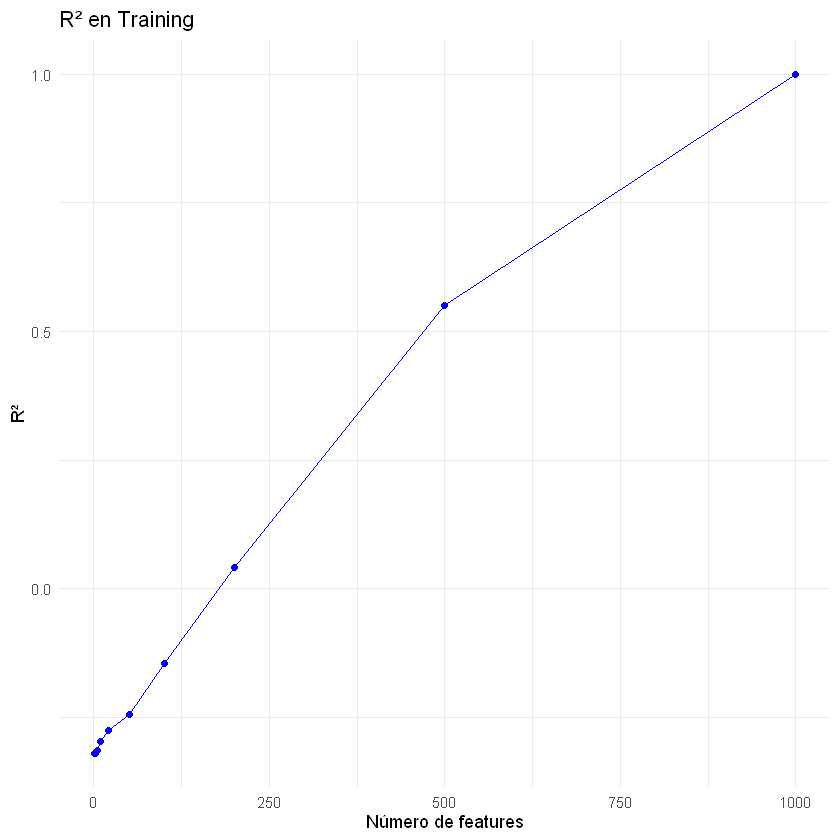

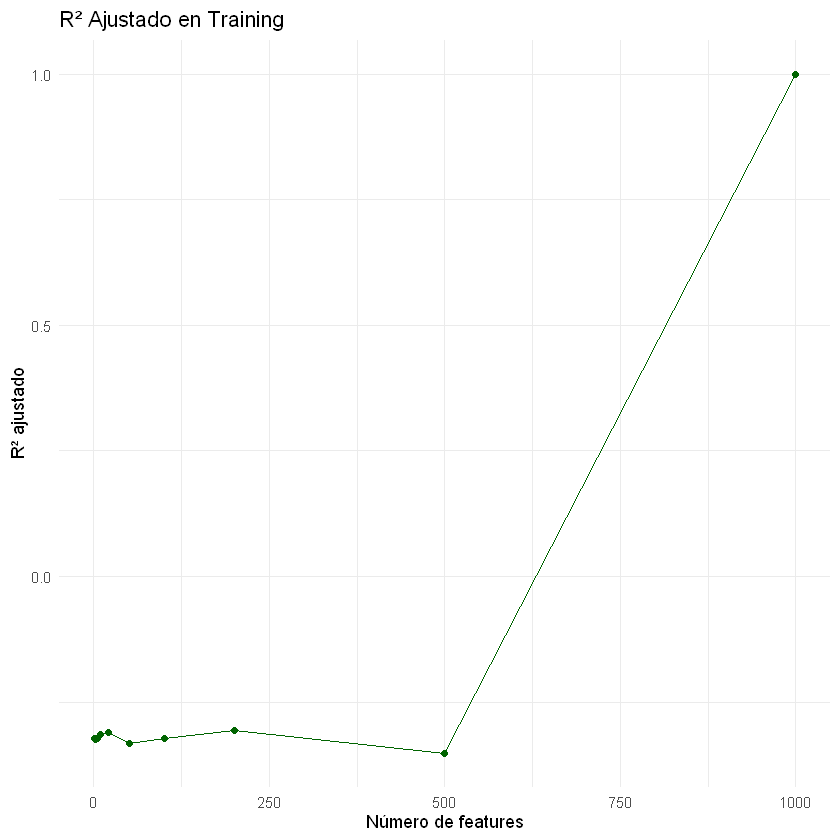

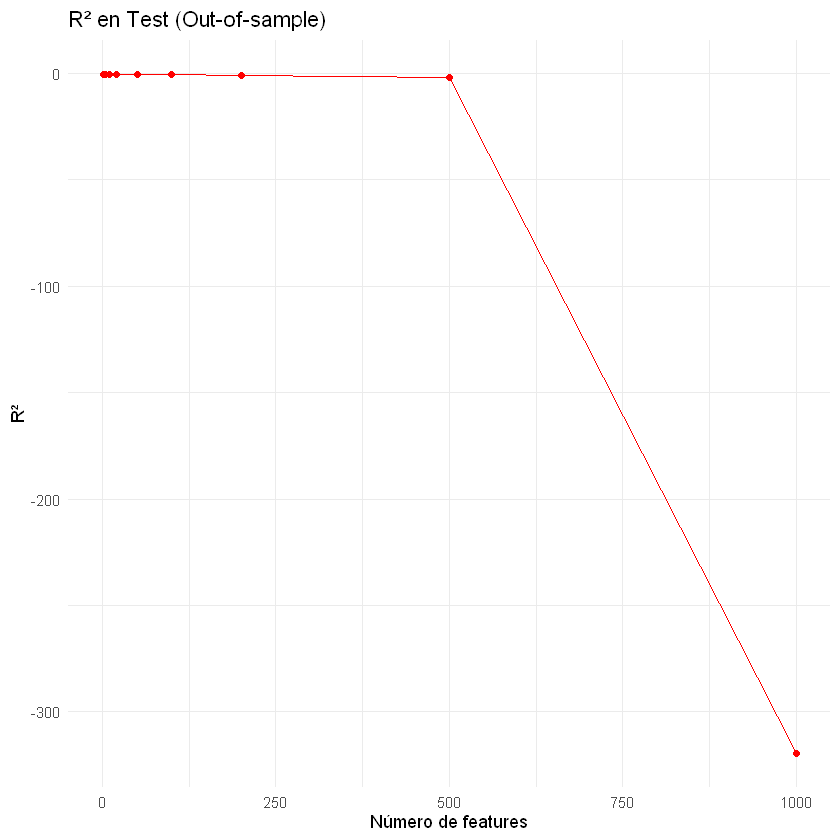

In [13]:

# ------------------------------------------------------------
# 6. Gráficos separados
# ------------------------------------------------------------
library(ggplot2)

# (a) R² Train
ggplot(results, aes(x=Features, y=R2_train)) +
  geom_line(color="blue") + geom_point(color="blue") +
  labs(title="R² en Training", x="Número de features", y="R²") +
  theme_minimal()

# (b) R² Ajustado
ggplot(results, aes(x=Features, y=R2_adj)) +
  geom_line(color="darkgreen") + geom_point(color="darkgreen") +
  labs(title="R² Ajustado en Training", x="Número de features", y="R² ajustado") +
  theme_minimal()

# (c) R² Test (out-of-sample)
ggplot(results, aes(x=Features, y=R2_test)) +
  geom_line(color="red") + geom_point(color="red") +
  labs(title="R² en Test (Out-of-sample)", x="Número de features", y="R²") +
  theme_minimal()

============================================================
Exercise 3
============================================================

In this section you'll need to do the following:

- Create a variable area2 that's the square of area (0.25 points)
- Convert 'hasparkingspace', 'hasbalcony', 'haselevator', 'hassecurity', 'hasstorageroom' to dummy variables (where 'yes' 'no' get mapped to 1, 0) (0.75 points)
- For each last digit of area (i.e. 0,1,...,9), create a dummy variable if the last digit of area happens to be that number. Name your variables accordingly (e.g. end_0, end_1, ...end_9). (1 point)

### Exercise 3a - Cleaning

1) Cargar datos

In [1]:
df <- read.csv("/Users/Dafne/Documents/GitHub/High_Dimensional_Linear_Models/R/input/apartments.csv")

2) Crear variable area2

In [2]:
df$area2 <- df$area^2

3) Convertir variables yes/no a 1/0

In [3]:
cols <- c("hasparkingspace", "hasbalcony", "haselevator", "hassecurity", "hasstorageroom")
df[cols] <- lapply(df[cols], function(x) ifelse(tolower(x) == "yes", 1, 0))


4) Crear dummies para el último dígito del área

In [4]:
df$area_last_digit <- df$area %% 10
for (d in 0:9) {
  df[[paste0("end_", d)]] <- ifelse(df$area_last_digit == d, 1, 0)
}
df$area_last_digit <- NULL  # eliminar columna auxiliar

### Exercise 3b - Linear Model Estimation

In [5]:
# Definir variables
last_digit_dummies <- paste0("end_", 0:8)  # end_9 será la categoría base
continuous_vars <- c("area", "area2",
                     "schooldistance", "clinicdistance", "postofficedistance",
                     "kindergartendistance", "restaurantdistance",
                     "collegedistance", "pharmacydistance")
binary_vars <- c("hasparkingspace", "hasbalcony", "haselevator", "hassecurity", "hasstorageroom")
categorical_vars <- c("month", "type", "rooms", "ownership", "buildingmaterial")

In [6]:
# Fórmula del modelo
formula <- as.formula(
  paste("price ~",
        paste(c(last_digit_dummies, continuous_vars, binary_vars,
                paste0("factor(", categorical_vars, ")")), collapse = " + "))
)

In [7]:
# Ajustar modelo OLS
model <- lm(formula, data = df)
summary(model)



Call:
lm(formula = formula, data = df)

Residuals:
     Min       1Q   Median       3Q      Max 
-1395903  -168244    -9358   147485  1893597 

Coefficients:
                                       Estimate Std. Error t value Pr(>|t|)    
(Intercept)                           1.127e+05  8.835e+03  12.758  < 2e-16 ***
end_0                                 1.813e+04  4.023e+03   4.507 6.57e-06 ***
end_1                                -1.612e+04  4.372e+03  -3.688 0.000226 ***
end_2                                 7.850e+03  4.153e+03   1.890 0.058708 .  
end_3                                 1.812e+04  4.239e+03   4.275 1.91e-05 ***
end_4                                -2.223e+02  4.139e+03  -0.054 0.957166    
end_5                                 1.658e+04  4.162e+03   3.984 6.79e-05 ***
end_6                                 2.936e+03  4.074e+03   0.721 0.471098    
end_7                                 1.677e+04  4.079e+03   4.111 3.94e-05 ***
end_8                                 1.3

### Exercise 3b - (Partialling-out)

In [9]:
# Instalación si no tienes fixest
install.packages("fixest")

library(fixest)

also installing the dependencies 'Formula', 'sandwich', 'dreamerr', 'stringmagic'




package 'Formula' successfully unpacked and MD5 sums checked
package 'sandwich' successfully unpacked and MD5 sums checked
package 'dreamerr' successfully unpacked and MD5 sums checked
package 'stringmagic' successfully unpacked and MD5 sums checked
package 'fixest' successfully unpacked and MD5 sums checked

The downloaded binary packages are in
	C:\Users\Dafne\AppData\Local\Temp\RtmpsLlQLw\downloaded_packages


In [10]:
# Ajustar con feols (permite partialling-out fácilmente)
formula_fe <- as.formula(
  paste("price ~ end_0 |",
        paste(c(continuous_vars, binary_vars,
                paste0("factor(", categorical_vars, ")")), collapse = " + "))
)

model_partial <- feols(formula_fe, data = df)
summary(model_partial)

NOTE: 3,257 observations removed because of NA values (Fixed-effects: 3,257).



OLS estimation, Dep. Var.: price
Observations: 106,934
Fixed-effects: area: 126,  area2: 126,  schooldistance: 1,924,  clinicdistance: 3,741,  postofficedistance: 2,132,  kindergartendistance: 1,689,  restaurantdistance: 1,811,  collegedistance: 4,607,  pharmacydistance: 1,784,  hasparkingspace: 2,  hasbalcony: 2,  haselevator: 2,  hassecurity: 2,  hasstorageroom: 2,  factor(month): 6,  factor(type): 4,  factor(rooms): 6,  factor(ownership): 3,  factor(buildingmaterial): 3
Standard-errors: Clustered (area) 
        Estimate Std. Error   t value Pr(>|t|) 
end_0 -112579456  888614529 -0.126691  0.89939 
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1
RMSE: 201,420.7     Adj. R2: 0.744164
                  Within R2: 1.469e-7

### Exercise 3c - Price Premium for end_0

In [11]:
# Filtrar dataset quitando los que terminan en 0
df_no_end0 <- subset(df, end_0 == 0)

In [12]:
# Misma fórmula, pero sin end_0
formula_no_end0 <- as.formula(
  paste("price ~",
        paste(c(paste0("end_", 1:8),
                continuous_vars, binary_vars,
                paste0("factor(", categorical_vars, ")")), collapse = " + "))
)

model_no_end0 <- lm(formula_no_end0, data = df_no_end0)
summary(model_no_end0)


Call:
lm(formula = formula_no_end0, data = df_no_end0)

Residuals:
     Min       1Q   Median       3Q      Max 
-1426717  -167634    -8972   146667  1886830 

Coefficients:
                                       Estimate Std. Error t value Pr(>|t|)    
(Intercept)                           1.268e+05  9.284e+03  13.661  < 2e-16 ***
end_1                                -1.586e+04  4.336e+03  -3.658 0.000254 ***
end_2                                 8.001e+03  4.119e+03   1.943 0.052057 .  
end_3                                 1.845e+04  4.204e+03   4.389 1.14e-05 ***
end_4                                 2.551e+00  4.105e+03   0.001 0.999504    
end_5                                 1.646e+04  4.127e+03   3.988 6.66e-05 ***
end_6                                 2.665e+03  4.040e+03   0.660 0.509493    
end_7                                 1.645e+04  4.046e+03   4.066 4.79e-05 ***
end_8                                -1.023e+02  3.952e+03  -0.026 0.979351    
area                     

In [13]:
# Predecir precios en toda la muestra usando este modelo
df$predicted_price_no_end0 <- predict(model_no_end0, newdata = df)

In [14]:
# Comparar promedios reales vs predichos para los deptos que terminan en 0
df_end0 <- subset(df, end_0 == 1)
avg_actual <- mean(df_end0$price, na.rm = TRUE)
avg_predicted <- mean(df_end0$predicted_price_no_end0, na.rm = TRUE)
difference <- avg_actual - avg_predicted

In [15]:
cat("Average actual price (end_0 = 1):", avg_actual, "\n")
cat("Average predicted price (end_0 = 1):", avg_predicted, "\n")
cat("Difference (real - predicted):", difference, "\n")

Average actual price (end_0 = 1): 873616.3 
Average predicted price (end_0 = 1): 857401 
Difference (real - predicted): 16215.3 


In [17]:
# ================================================
# Guardar outputs en la carpeta "output"
# ================================================

# Definir carpeta de salida
output_dir <- "C:/Users/Dafne/Documents/GitHub/High_Dimensional_Linear_Models/R/output"

# Extraer coeficientes como data.frame
res_3b1 <- as.data.frame(summary(model)$coefficients)
res_3b2 <- as.data.frame(summary(model_partial)$coeftable)
res_3c  <- as.data.frame(summary(model_no_end0)$coefficients)

# Guardar cada uno en CSV
write.csv(res_3b1, file = file.path(output_dir, "3b1_results.csv"))
write.csv(res_3b2, file = file.path(output_dir, "3b2_results.csv"))
write.csv(res_3c,  file = file.path(output_dir, "3c_results.csv"))

# Guardar diferencias calculadas en un archivo aparte
premium_results <- data.frame(
  avg_actual = avg_actual,
  avg_predicted = avg_predicted,
  difference = difference
)
write.csv(premium_results, file = file.path(output_dir, "3c_price_premium.csv"), row.names = FALSE)

cat("✅ Resultados exportados a la carpeta output\n")


✅ Resultados exportados a la carpeta output


In [18]:
# ================================================
# Guardar outputs en archivo .txt
# ================================================

# Definir carpeta de salida
output_dir <- "C:/Users/Dafne/Documents/GitHub/High_Dimensional_Linear_Models/R/output"
if (!dir.exists(output_dir)) dir.create(output_dir, recursive = TRUE)

# Redirigir todo el output a un archivo
sink(file.path(output_dir, "exercise3_output.txt"))

cat("=== Resultados 3b1 - Modelo OLS ===\n")
print(summary(model))

cat("\n\n=== Resultados 3b2 - Partialling-out (feols) ===\n")
print(summary(model_partial))

cat("\n\n=== Resultados 3c - Modelo sin end_0 ===\n")
print(summary(model_no_end0))

cat("\n\n=== Comparación promedio real vs predicho (end_0) ===\n")
cat("Average actual price (end_0 = 1):", avg_actual, "\n")
cat("Average predicted price (end_0 = 1):", avg_predicted, "\n")
cat("Difference (real - predicted):", difference, "\n")

# Cerrar el sink (muy importante)
sink()
